<a href="https://colab.research.google.com/github/MetehanBB/GROUP36_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: EDA ve Baseline

**Yarışma:** [Deep Past Challenge – Translate Akkadian to English](https://www.kaggle.com/c/deep-past-initiative-machine-translation)
**Grup:** GROUP36 (CENG313) — Metehan Bölükbaşı, Mustafa Karadeniz

Bu notebook yedi bölümden oluşur:

1. Problem definition (Problem tanımı)
2. Data overview (Veriye genel bakış)
3. Exploratory data analysis (Keşifsel veri analizi)
4. Preprocessing (Ön işleme)
5. Baseline model (Temel model)
6. Kaggle submission (Kaggle teslimi)
7. Conclusion (Sonuç)

Notebook yalnızca hikâyeyi anlatır. Tekrar kullanılan tüm kod `src/` klasöründedir: `src/data.py` (yükleme, temizleme, bölme), `src/models.py` (baseline modelleri) ve `src/utils.py` (metrik, grafikler, submission).

## 0. Kurulum

In [1]:
import os
import subprocess
import sys

REPO = "GROUP36_CENG313"
URL = "https://github.com/MetehanBB/GROUP36_CENG313.git"
BRANCH = "main"  # main'e henüz birleştirilmemiş bir dalı denemek için burayı o dalın adı yapın

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Colab: repoyu klonla (zaten içindeysek tekrar klonlama), son hâlini çek, paketleri kur
    if os.path.basename(os.getcwd()) != REPO:
        if not os.path.exists(REPO):
            subprocess.run(["git", "clone", "-b", BRANCH, URL], check=True)
        os.chdir(REPO)
    subprocess.run(["git", "pull", "origin", BRANCH])
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

sys.path.insert(0, os.getcwd())
print("Ortam:", "Google Colab" if IN_COLAB else "yerel", "| çalışma klasörü:", os.path.basename(os.getcwd()))

Ortam: yerel | çalışma klasörü: GROUP36_CENG313


In [2]:
import pandas as pd
from IPython.display import display

from src.data import SRC_COL, TGT_COL, clean_akkadian_text, load_data, preprocess, split_data
from src.models import (compare_length_caps, compare_settings, predict, robustness_to_h_spelling,
                        run_baselines, tokenization_demo, train_baseline)
from src.utils import (add_length_features, before_after, build_kaggle_notebook, char_inventory_diff,
                       compute_metrics, conflicting_sources, data_overview, determinative_table,
                       duplicate_report, extreme_examples, gap_summary, length_correlations,
                       length_ratio_summary, notation_table, outlier_summary, plot_baseline_scores,
                       plot_boxplots,
                       plot_determinative_words, plot_distributions, plot_length_relationship,
                       plot_top_tokens, preprocessing_effect, sample_overlap, save_submission,
                       set_plot_style, show_predictions, token_type_table, validate_submission,
                       vocab_stats)

set_plot_style()
pd.set_option("display.max_colwidth", 160)
print("Kütüphaneler ve src modülleri yüklendi.")

Kütüphaneler ve src modülleri yüklendi.


## 1. Problem definition (Problem tanımı)

**Görev.** Yaklaşık 4000 yıl önce Asurlu tüccarların kil tabletlere yazdığı Eski Asurca (Akadcanın bir lehçesi) ticari metinleri İngilizceye çevirmek. Bu bir **makine çevirisi** (sequence-to-sequence) problemidir: girdi bir metin, çıktı başka bir metin.

| | |
|---|---|
| **Girdi** | Tabletin Latin harfli **transliterasyonu** (çivi yazısı işaretlerinin hece hece okunuşu), örn. `1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé` |
| **Hedef değişken** | Metnin **İngilizce çevirisi** (`translation` sütunu), örn. *"Itūr-ilī has received one textile of ordinary quality."* |
| **Problem türü** | Düşük kaynaklı dilde makine çevirisi (yalnızca 1561 çevirili belge) |

**Değerlendirme metriği.** Kaggle, BLEU ve chrF++ skorlarının **geometrik ortalamasını** kullanır:

$$\text{Score} = \sqrt{\text{BLEU} \times \text{chrF++}}$$

- **BLEU**: tahmindeki kelime n-gramlarının (1-4) referansla ne kadar örtüştüğünü ölçer; kelimeyi birebir tutturmayı ödüllendirir.
- **chrF++**: karakter n-gramları (ve kelime 1-2 gramları) üzerinden F-skoru hesaplar; özel isimlerde küçük yazım farklarını (*Aššur* / *Assur*) BLEU kadar sert cezalandırmaz.
- İkisi de tüm korpus üzerinden tek seferde (**mikro ortalama**) `sacrebleu` ile hesaplanır ve 0-100 aralığındadır.
- **Neden geometrik ortalama?** Skorlardan biri düşükse sonuç da düşük kalır. Yalnızca karakter düzeyinde benzeyen ama kelimeleri tutturamayan (ya da tersi) bir sistem yüksek puan alamaz; iki ölçütte de dengeli olmak gerekir.

Metrik `src/utils.py` içindeki `compute_metrics` fonksiyonuyla hesaplanır. Aşağıdaki küçük örnek metriğin nasıl davrandığını gösterir.

In [3]:
referans = ["Seal of Puzur-Aššur son of Ataya.", "He will pay in 14 weeks."]
tahminler = {
    "Birebir aynı": referans,
    "Kısmen doğru": ["Seal of Puzur-Aššur, son of Ali-ahum.", "He will pay 14 shekels."],
    "Alakasız": ["To Ennānum from Šalim-Aššur.", "I sent you silver."],
}
pd.DataFrame({ad: compute_metrics(tahmin, referans) for ad, tahmin in tahminler.items()}).T.round(2)

,BLEU,chrF++,Score
Birebir aynı,100.00,100.00,100.00
Kısmen doğru,25.29,60.70,39.18
Alakasız,4.26,13.38,7.55


**Yorum:** Birebir aynı çeviri 100 alır. Kısmen doğru çeviride chrF++, BLEU'dan belirgin biçimde yüksektir: karakter düzeyindeki benzerlik kelime düzeyindeki örtüşmeden daha kolay kazanılır. Alakasız çeviride BLEU sıfıra yakın kaldığı için chrF++ bir miktar puan verse bile geometrik ortalama dibe çekilir. Bu, ileride baseline skorlarını okurken önemli olacak: chrF++ tek başına iyimser bir tablo çizer.

## 2. Data overview (Veriye genel bakış)

Veri `data/` klasöründen okunur (`src/data.py` → `load_data`). Klasör Git'e eklenmez; veri yoksa fonksiyon Kaggle API ile indirmeyi dener.

In [4]:
train_df, test_df, sample_sub = load_data()

print(f"train.csv            : {train_df.shape[0]} satır x {train_df.shape[1]} sütun")
print(f"test.csv             : {test_df.shape[0]} satır x {test_df.shape[1]} sütun")
print(f"sample_submission.csv: {sample_sub.shape[0]} satır x {sample_sub.shape[1]} sütun")

train.csv            : 1561 satır x 3 sütun
test.csv             : 4 satır x 5 sütun
sample_submission.csv: 4 satır x 2 sütun


In [5]:
train_df.head(3)

,oare_id,transliteration,translation
0,004a7dbd-57ce-46f8-9691-409be61c676e,KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-{d}IM KIŠIB šu-{d}EN.LÍL DUMU ma-nu-ki-a-šur KIŠIB MAN-a-šur DUMU a-ta-a 0.3333 ma-na 2 GÍN KÙ.BABBAR SIG₅ i-ṣé-er PUZUR...,"Seal of Mannum-balum-Aššur son of Ṣilli-Adad, seal of Šu-Illil son of Mannum-kī-Aššur, seal of Puzur-Aššur son of Ataya. Puzur-Aššur son of Ataya owes 22 sh..."
1,0064939c-59b9-4448-a63d-34612af0a1b5,1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé,Itūr-ilī has received one textile of ordinary quality.
2,0073f2c0-524c-4bbf-915a-8c1772a4fb98,TÚG u-la i-dí-na-ku-um i-tù-ra-ma 9 GÍN KÙ.BABBAR,<gap> he did not give you a textile. He returned and 9 shekels of silver <gap>


Her satır bir **tablet (belge)**: `oare_id` belgenin kimliği, `transliteration` Akadca kaynak metin, `translation` İngilizce hedef metin.

Yarışma verisinde bu üç dosyanın yanında yardımcı kaynaklar da var; Assignment 1'de kullanılmadılar, Assignment 2 için adaylar:

| Dosya | İçerik |
|---|---|
| `published_texts.csv` | Yaklaşık 8000 tabletin transliterasyonu ve üst verisi (çoğunun çevirisi yok) |
| `Sentences_Oare_FirstWord_LinNum.csv` | Bazı tabletler için cümle düzeyinde çeviriler ve cümlenin ilk kelimesinin konumu |
| `OA_Lexicon_eBL.csv`, `eBL_Dictionary.csv` | Eski Asurca sözlük ve özel isim listeleri |
| `publications.csv`, `bibliography.csv`, `resources.csv` | Akademik yayınların OCR metinleri ve kaynakça |

### 2.1 Veri tipleri, eksik değerler, `describe()`

In [6]:
print("train.csv")
display(data_overview(train_df))
print("test.csv")
display(data_overview(test_df))

train.csv


,veri tipi,dolu,eksik,eksik %,benzersiz
oare_id,str,1561,0,0.0,1561
transliteration,str,1561,0,0.0,1559
translation,str,1561,0,0.0,1557


test.csv


,veri tipi,dolu,eksik,eksik %,benzersiz
id,int64,4,0,0.0,4
text_id,str,4,0,0.0,1
line_start,int64,4,0,0.0,4
line_end,int64,4,0,0.0,4
transliteration,str,4,0,0.0,4


In [7]:
train_df.describe()

,oare_id,transliteration,translation
count,1561,1561,1561
unique,1561,1559,1557
top,004a7dbd-57ce-46f8-9691-409be61c676e,40 ma-na KÙ.BABBAR ni-is-ḫa-sú DIRI ša-du-a-sú ša-bu en-um-a-šùr a-na a-lu-a ù e-ni-ša-ru-um i-na ša-la-tù-ar ku-nu-ki ip-qí-id um-ma šu-ut-ma a-na a-lim{ki...,"4 talents 42 minas of copper with Iddin-Aurum. 0.5 mina of silver, working capital of Kitaya. 8 minas of silver with Šuli, son of Puzur-Abeh. 4 minas 3.8333..."
freq,1,2,2


In [8]:
train_len = add_length_features(train_df)
LEN_COLS = ["src_chars", "tgt_chars", "src_words", "tgt_words", "char_ratio", "word_ratio"]
uzunluk_ozeti = train_len[LEN_COLS].describe()
uzunluk_ozeti.loc["skew (çarpıklık)"] = train_len[LEN_COLS].skew()
uzunluk_ozeti.round(2)

,src_chars,tgt_chars,src_words,tgt_words,char_ratio,word_ratio
count,1561.00,1561.00,1561.00,1561.00,1561.00,1561.00
mean,428.82,500.42,56.16,89.99,1.09,1.49
std,270.43,467.49,35.51,84.96,0.49,0.68
min,21.00,6.00,3.00,1.00,0.01,0.01
25%,206.00,174.00,27.00,30.00,0.98,1.28
50%,371.00,383.00,49.00,68.00,1.08,1.48
75%,636.00,680.00,83.00,124.00,1.18,1.66
max,966.00,3995.00,150.00,739.00,9.25,11.00
skew (çarpıklık),0.44,2.34,0.52,2.34,6.44,4.44


**Yorum:**

- **Boyut.** Train'de 1561 belge ve 3 sütun var. Bir çeviri modeli için bu çok küçük bir paralel veri; problem "düşük kaynaklı" sınıfına giriyor.
- **Veri tipleri.** Üç sütun da metin. Sayısal özellik yok; bu yüzden klasik `describe()` yalnızca sayım, benzersiz değer ve en sık değeri verir. Sayısal özet için metinlerden uzunluk özellikleri türettik: `src_*` kaynak (transliterasyon), `tgt_*` hedef (çeviri), `char_ratio` ve `word_ratio` = çevirinin karakter / kelime sayısının kaynağınkine oranı. Son satır çarpıklık (skew): 0'a yakın değer simetrik, büyük pozitif değer uzun sağ kuyruklu dağılım demek.
- **Eksik değer.** Hiçbir sütunda eksik değer yok (train ve test).
- **Uzunluklar.** Kaynak ortalama 429 karakter (medyan 371), hedef ortalama 500 karakter (medyan 383). Kaynak en fazla 966 karakter iken hedef 3995 karaktere kadar çıkıyor; bu dengesizliğe EDA'da döneceğiz.
- `oare_id` 1561 satırda 1561 farklı değer alıyor: her belge bir kez geçiyor.

### 2.2 Tekrar eden kayıtlar

In [9]:
duplicate_report(train_df)

,adet
Tam satır tekrarı,0
Tekrar eden transliterasyon,2
Tekrar eden çeviri,4
"Çelişkili kaynak (aynı transliterasyon, farklı çeviri)",2


**Yorum:** Birebir aynı satır yok. Yalnızca 2 transliterasyon ve 4 çeviri birden fazla kez geçiyor; veri neredeyse tekrarsız. Tekrar eden 2 transliterasyonun ikisinde de çeviriler farklı ("çelişkili kaynak"); bunları 3.9'da inceliyoruz.

### 2.3 Train ve test aynı biçimde değil

In [10]:
print("test.csv (public örnek)")
display(test_df)
print("sample_submission.csv")
display(sample_sub)

test.csv (public örnek)


,id,text_id,line_start,line_end,transliteration
0,0,332fda50,1,7,um-ma kà-ru-um kà-ni-ia-ma a-na aa-qí-il… da-tim aí-ip-ri-ni kà-ar kà-ar-ma ú wa-bar-ra-tim qí-bi„-ma mup-pu-um aa a-lim(ki) i-li-kam
1,1,332fda50,7,14,i-na mup-pì-im aa a-lim(ki) ia-tù u„-mì-im a-nim ma-ma-an KÙ.AN i-aa-ú-mu-ni i-na né-mì-lim da-aùr ú-lá e-WA ia-ra-tí-au kà-ru-um kà-ni-ia i-lá-qé
2,2,332fda50,14,24,ki-ma mup-pì-ni ta-áa-me-a-ni a-ma-kam lu a-na aí-mì-im a-na É.GAL-lim i-dí-in lu té-ra-at É.GAL-lim ú-kà-lim lu na-aí-ma a-dí-ni lá i-dí-in ma-lá KÙ.AN na-...
3,3,332fda50,25,30,me-+e-er mup-pì-ni a-na kà-ar kà-ar-ma ú wa-bar-ra-tim aé-bi„-lá KÙ.AN lu a-na DAM.GÀR-ru-tim i-dí-in au-mì a-wi-lim lu-up-ta-nim


sample_submission.csv


,id,translation
0,0,"Thus Kanesh, say to the -payers, our messenger, every single colony, and the trading stations: A letter of the City has arrived."
1,1,"In the letter of the City (it is written): From this day on, whoever buys meteoric iron, (the City of) Assur is not part of the profit made, the tithe on it..."
2,2,"As soon as you have heard our letter, who(ever) over there has either sold it to a palace, or has offered it to palace officials, or still carries it with h..."
3,3,"Send a copy of (this) letter of ours to every single colony and to all the trading stations. Even when somebody has sold meteoric iron via a trading agent, ..."


In [11]:
sample_overlap(train_df, sample_sub)

,id,örnek çeviri (başı),train'de geçtiği belge sayısı,train satır indeksi
0,0,"Thus Kanesh, say to the -payers, our messenger, every singl…",1,406
1,1,"In the letter of the City (it is written): From this day on,…",1,406
2,2,"As soon as you have heard our letter, who(ever) over there h…",1,406
3,3,Send a copy of (this) letter of ours to every single colony …,1,406


**Yorum:** Burada üç önemli gözlem var.

1. **Train belge düzeyinde, test cümle düzeyinde.** Train'de her satır bir tabletin tamamı. Test'te ise her satır aynı tabletin (`text_id`) bir parçası; `line_start` ve `line_end` parçanın hangi satırları kapsadığını söylüyor. Model belge görerek kurulacak ama cümle çevirmesi istenecek.
2. **Public `test.csv` yalnızca 4 satırlık bir örnek.** Gerçek test kümesi gizli; gönderilen notebook Kaggle'da çalışırken bu dosyanın yerine konuyor.
3. **Bu 4 örnek cümle train'in içinde.** Yukarıdaki tablo, dört örnek çevirinin de train'deki tek bir belgenin (satır 406) çevirisinin parçaları olduğunu gösteriyor. Yani örnek test üzerinde skor hesaplamak **sızıntılı** olur ve yanıltır. Bu yüzden notebook'ta örnek testi yalnızca biçim kontrolü için kullanıyor, skorları kendi ayırdığımız bölmelerde raporluyoruz.

## 3. Exploratory data analysis (Keşifsel veri analizi)

Bu bölümde renkler sabit: **mavi** Akadca transliterasyonu (kaynak), **turuncu** İngilizce çeviriyi (hedef) gösterir.

### 3.1 Karakter uzunluğu dağılımı

,belge sayısı,belge %,oran medyanı,oran < 0.5 (belge),oran > 2 (belge)
kaynak uzunluğu (karakter),,,,,
< 850,1346,86.2,1.07,107,9
850-899,137,8.8,1.37,1,17
900+,78,5.0,1.22,2,7
tümü,1561,100.0,1.08,110,33


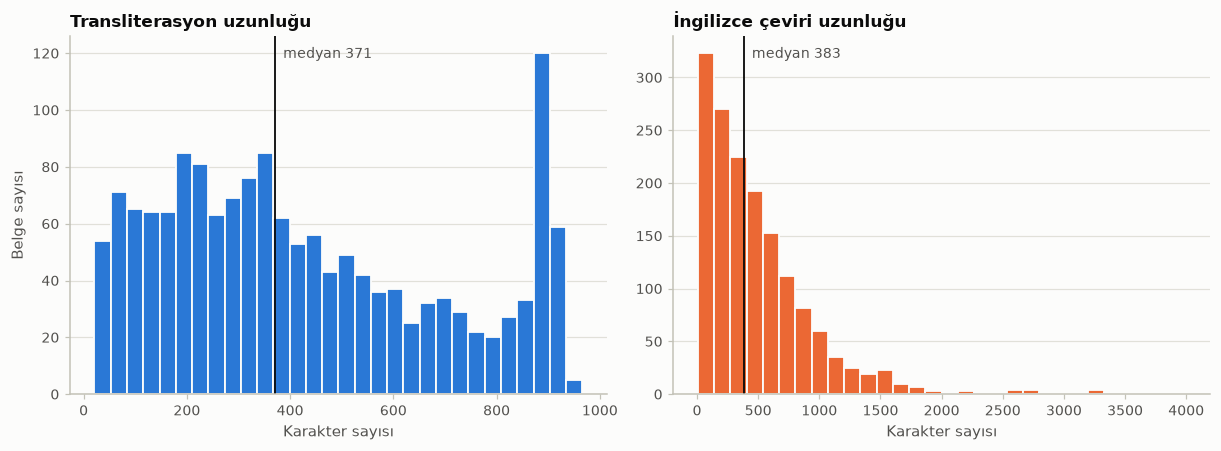

In [12]:
display(length_ratio_summary(train_len))
plot_distributions(train_len, ["src_chars", "tgt_chars"],
                   ["Transliterasyon uzunluğu", "İngilizce çeviri uzunluğu"],
                   xlabel="Karakter sayısı")

**Yorum:** Transliterasyon uzunluğu 21 ile 966 karakter arasında, medyan 371. Dağılım 50-400 karakter arasında geniş bir tepe yapıp azalıyor; ama **870-935 karakter aralığında ani bir yığılma** var (en yüksek sütun tek başına yaklaşık 120 belge) ve 966'dan uzun hiçbir belge yok. Tabloya göre 850-899 karakter aralığında 137, 900 ve üstünde 78 belge var; yani belgelerin %13.8'i (215 belge) 850 karakterin üstünde, son 116 karakterlik dar bir bantta toplanmış. Doğal bir uzunluk dağılımı böyle keskin bir duvara çarpmaz: uzun tabletlerin transliterasyonu büyük olasılıkla belirli bir uzunlukta **kesilmiş**. İngilizce çeviri ise tipik bir sağa çarpık dağılım: medyan 383, ama kuyruk 3995 karaktere kadar uzanıyor (2.1'deki tabloda çarpıklık 2.34, kaynakta yalnızca 0.44) ve kesme izi yok. Yani uzun belgelerde kaynak eksik, çeviri tam olabilir; bunu 3.3 ve 3.4'te sınıyoruz.

### 3.2 Kelime uzunluğu dağılımı

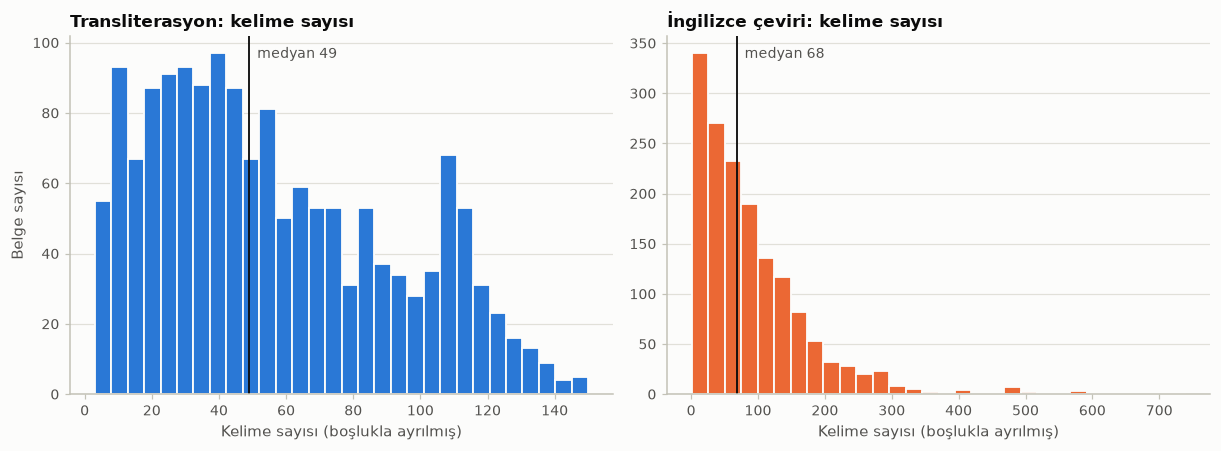

In [13]:
plot_distributions(train_len, ["src_words", "tgt_words"],
                   ["Transliterasyon: kelime sayısı", "İngilizce çeviri: kelime sayısı"],
                   xlabel="Kelime sayısı (boşlukla ayrılmış)")

**Yorum:** Kelime sayısında da aynı tablo: transliterasyon medyan 49 kelime (en fazla 150), çeviri medyan 68 kelime (en fazla 739). Transliterasyonda 105-115 kelime civarında ikinci bir tepe var; bu, karakter grafiğindeki yığılmanın kelime karşılığı. Belge başına İngilizce / Akadca kelime oranının medyanı 1.48 (2.1'deki `word_ratio`): bir Akadca kelime ortalama bir buçuk İngilizce kelimeye karşılık geliyor. Nedeni Akadcanın bitişken yapısı: `i-ša-qal` tek kelime, karşılığı "he will pay" üç kelime. Karakter sayıları ise birbirine çok yakın (oranın medyanı 1.08). İki dil karakter düzeyinde benzer uzunlukta, kelime düzeyinde değil; bu, kelime yerine karakter ya da bayt düzeyinde çalışan modeller (ör. ByT5) lehine bir işaret.

### 3.3 Aykırı değerler: çok kısa ve çok uzun belgeler

,Q1,medyan,Q3,üst sınır,aykırı adet,aykırı %,maksimum
src_chars,206.0,371.0,636.0,1281.0,0,0.00,966
tgt_chars,174.0,383.0,680.0,1439.0,68,4.36,3995
src_words,27.0,49.0,83.0,167.0,0,0.00,150
tgt_words,30.0,68.0,124.0,265.0,64,4.10,739


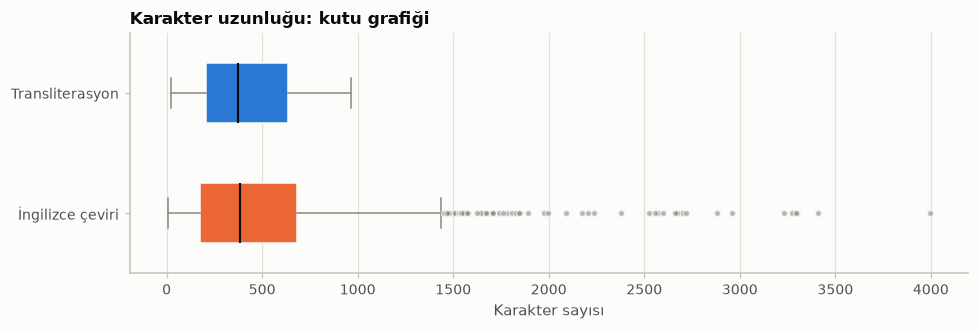

In [14]:
display(outlier_summary(train_len, ["src_chars", "tgt_chars", "src_words", "tgt_words"]))
plot_boxplots(train_len, ["src_chars", "tgt_chars"], ["Transliterasyon", "İngilizce çeviri"],
              title="Karakter uzunluğu: kutu grafiği", xlabel="Karakter sayısı")

**Yorum:** IQR kuralına göre (Q3 + 1.5 × IQR üstü) transliterasyonda **hiç aykırı değer yok**: üst sınır 1281 karakter, en uzun belge 966. Bu, verinin temiz olduğunu değil üstten kesildiğini gösteriyor; mavi kutunun bıyığı 966'da aniden bitiyor. Çeviride üst sınır 1439 karakter ve bunu aşan **68 belge (%4.36)** var; noktalar 4000 karaktere kadar uzanıyor. Kelime sayısında da aynı: çeviride 64 aykırı belge (%4.10), kaynakta sıfır. Alt uçta aykırı değer yok. İki kutunun gövdesi (çeyrekler arası) neredeyse üst üste; fark yalnızca kuyrukta.

In [15]:
print("En kısa 3 transliterasyon")
display(extreme_examples(train_len, "src_chars", largest=False))
print("En uzun 3 çeviri")
display(extreme_examples(train_len, "tgt_chars", largest=True))

En kısa 3 transliterasyon


,src_chars,tgt_chars,transliteration,translation
375,21,34,6 ku-ta-nu ša DAM.GÀR,6 kutānus belonging to a merchant.
125,24,33,a-ta-lá-ak ú-zu-ni pé-té,<gap> I shall go <gap> Inform us.
670,26,40,DUB ḫa-ru-mu-tum ša nu-a-e,Certified tablets concerning Anatolians.


En uzun 3 çeviri


,src_chars,tgt_chars,transliteration,translation
177,935,3995,ša 4 ma-na KÙ.BABBAR ša en-na-sú-in a-na a-bi-ni i-ḫi-ib-lu-ni 2.5 ma-na KÙ.BABBAR ṣí-ib-tám 0.5 ma-,"As to the 4 minas of silver that Enna-Suen owed to our father, 2.5 minas of silver, interest, 0.5 mi"
1090,906,3408,um-ma a-šùr-ma-lik ù ša-lim-a-šur a-na ša-lim-a-šur qí-bi-ma la-ma a-šur-ša-du-e i-li-kà-ma lá-ma ṭu,From Aššur-malik and Šalim-Aššur to Šalim-Aššur: Before Aššur-šadue came and before he brought your
1377,834,3297,<gap> na <gap> PÚZUR-a-šùr DUMU a-ḫu-wa-qar iš-tù <gap> ub-lu-ni-ni ŠÀ.BA 4 TÚG.ḪI.A <gap> iṣ-ḫi-ru-,"<gap> Puzur-Aššur(?), son of Ahu-waqar <gap> brought here. Thereof 4 textiles<gap> were deducted. Th"


**Yorum:** En kısa transliterasyonlar 21-26 karakter ve anlamlı kısa kayıtlar (*"6 kutānus belonging to a merchant."*); hatalı satır değiller, atılmaları gerekmiyor. En uzun üç çeviri 3297-3995 karakter, ama transliterasyonları yalnızca 834-935 karakter: çeviri kaynağın 3.8-4.3 katı. Sağlıklı belgelerde bu oran 1.1 civarında. Yani bu belgelerde çeviri tabletin tamamını, transliterasyon yalnızca baş kısmını içeriyor. Böyle çiftler modele "kısa girdiden uzun çıktı üret" diye yanlış bir sinyal verir; Assignment 2'de bu belgeleri ayıklamak ya da çeviriyi de kısaltmak gerekecek.

### 3.4 Kaynak ve hedef uzunluğu arasındaki ilişki

,src_chars ~ tgt_chars
Pearson,0.814
Spearman,0.914


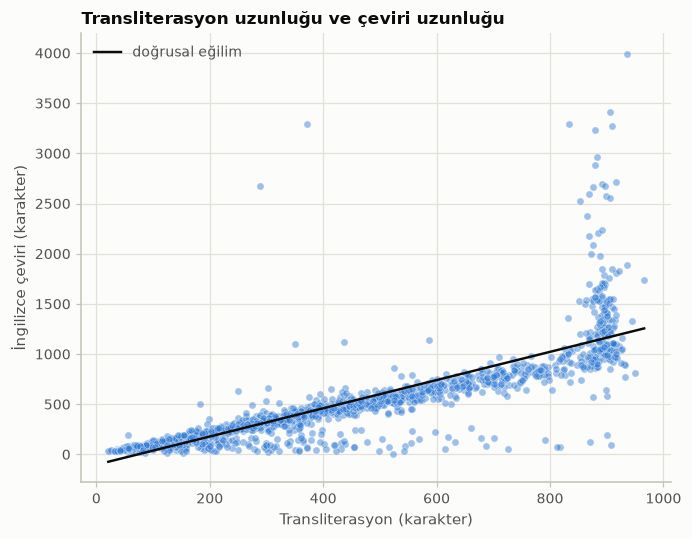

In [16]:
display(length_correlations(train_len, "src_chars", "tgt_chars"))
plot_length_relationship(train_len, "src_chars", "tgt_chars",
                         xlabel="Transliterasyon (karakter)", ylabel="İngilizce çeviri (karakter)",
                         title="Transliterasyon uzunluğu ve çeviri uzunluğu")

**Yorum:** Uzunluklar arasında güçlü bir ilişki var: Pearson 0.814, Spearman 0.914. Spearman'ın daha yüksek olması ilişkinin monoton ama tam doğrusal olmadığını söylüyor. Grafikte üç bölge görülüyor:

1. **Ana bant.** Belgelerin çoğu orijinden çıkan dar bir bant üzerinde: çeviri uzunluğu ≈ 1.08 × kaynak uzunluğu (oranın medyanı 1.08, çeyrekleri 0.98 ve 1.18). Doğrusal eğilim çizgisi bu bandı izliyor.
2. **870-935 karakterde dikey sütun.** Kaynak uzunluğu neredeyse sabitken çeviri yaklaşık 800'den 4000 karaktere kadar dağılıyor. Bu, 3.1'deki kesme hipotezini destekliyor: 3.1'deki tabloya göre çeviri / kaynak oranının medyanı 850 karakterin altında 1.07 iken 850-899 grubunda 1.37'ye, 900+ grubunda 1.22'ye çıkıyor; oranı 2'nin üstünde olan 33 belgenin 24'ü bu iki grupta (belgelerin yalnızca %13.8'i burada olduğu hâlde).
3. **Bandın altındaki noktalar.** 3.1'deki tablonun "tümü" satırına göre 110 belgede (%7.0) çeviri kaynağın yarısından kısa; bunlar büyük olasılıkla ağır hasarlı ya da yalnızca kısmen çevrilmiş tabletler.

Sonuç: uzunluk iyi bir ipucu ama kesilmiş belgelerde güvenilir değil. Yine de "çıktı, girdinin birkaç katından uzun olmamalı" gibi kaba bir üst sınır koymak için kullanılabilir; bunu 5.3'te kullanıyoruz.

### 3.5 En sık geçen kelimeler ve sözlük boyutu

,toplam token,farklı token,bir kez geçen token,bir kez geçenlerin payı %,token / farklı token
transliterasyon,87662,11583,6874,59.3,7.6
çeviri,140471,10053,5265,52.4,14.0


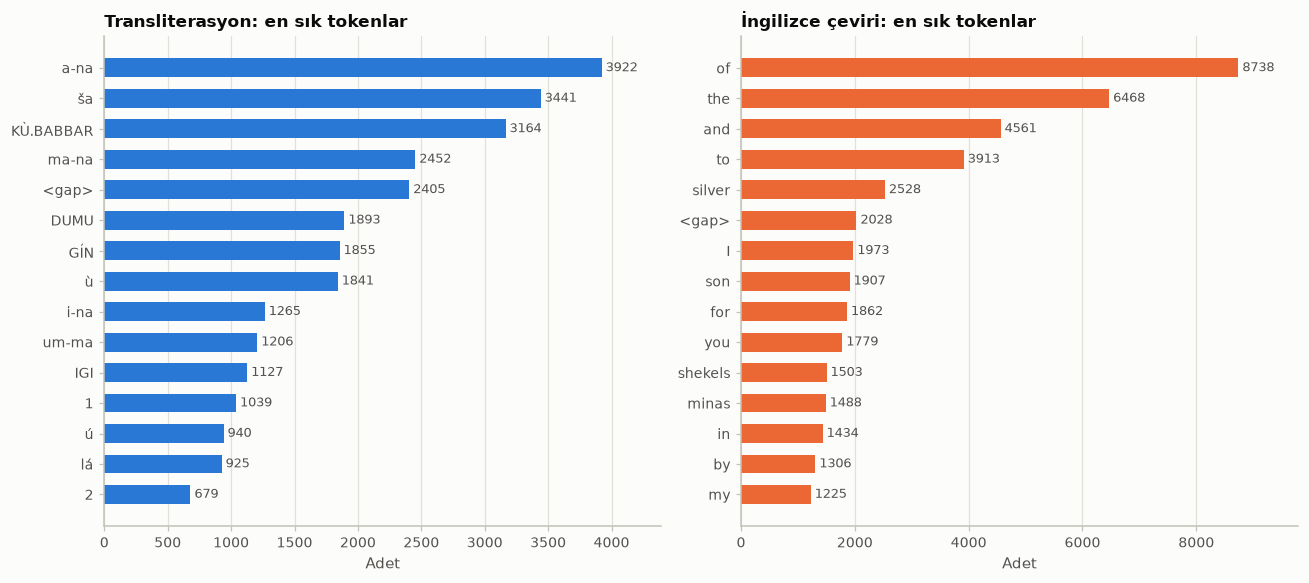

In [17]:
display(vocab_stats({"transliterasyon": train_df[SRC_COL], "çeviri": train_df[TGT_COL]}))
plot_top_tokens(train_df[SRC_COL], train_df[TGT_COL], n=15)

**Yorum:** Transliterasyonda en sık tokenlar üç gruba ayrılıyor: işlev kelimeleri (`a-na` "-e / için", `ša` "-nin", `ù` "ve", `i-na` "içinde", `um-ma` "şöyle"), ticaret terimleri (`KÙ.BABBAR` "gümüş", `ma-na` "mina", `GÍN` "şekel", `DUMU` "oğul", `IGI` "tanık") ve sayılar. İngilizce tarafta bunların karşılıkları da listede: *silver* (2528), *son* (1907), *shekels* (1503), *minas* (1488). Metinler borç senedi, mühür listesi, mektup gibi **kalıplaşmış ticari belgeler**; bu, benzer belgeyi bulup çevirisini getiren basit bir yöntemin bile işe yarayabileceğini düşündürüyor. `<gap>` iki tarafta da ilk altıda.

Sözlük tarafında durum zor: transliterasyonda 87662 tokenın 11583'ü farklı ve bunların **%59.3'ü yalnızca bir kez geçiyor**; çeviride oran %52.4. Bir Akadca token ortalama 7.6 kez görülüyor (İngilizcede 14.0). Kelime düzeyinde çalışan bir model testte sürekli hiç görmediği kelimelerle karşılaşacak; alt-kelime ya da karakter düzeyinde temsil gerekiyor.

### 3.6 Token türleri ve determinatifler

,token türü,adet,pay %
0,Hece yazımı (küçük harf),62085,70.8
1,Sümerogram (tamamı BÜYÜK harf),13481,15.4
2,Sayı,6487,7.4
3,Karışık (logogram + hece),3200,3.7
4,Kırık işareti (<gap>),2405,2.7
5,Diğer,4,0.0


,determinatif,adet,geçtiği belge,belge %
0,{d},482,332,21.3
1,{ki},383,250,16.0


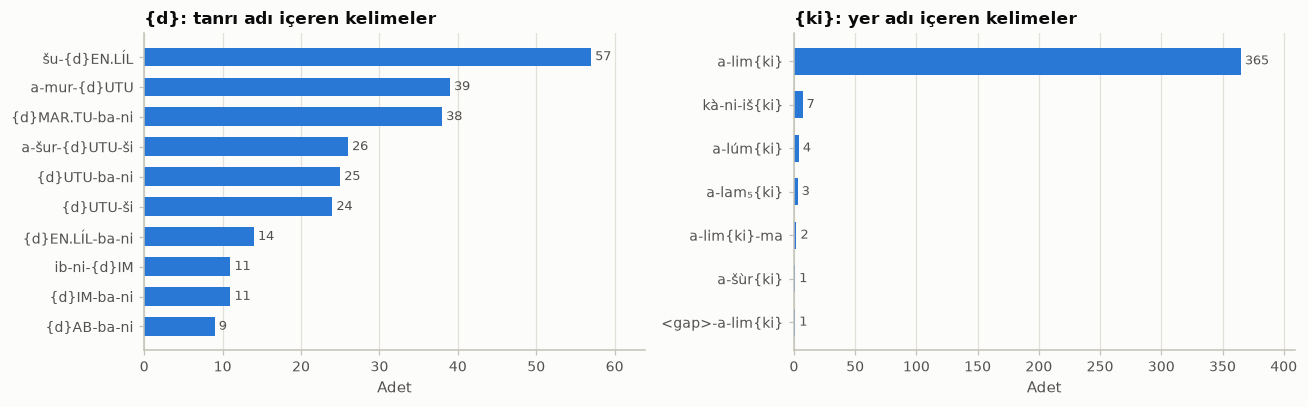

In [18]:
display(token_type_table(train_df[SRC_COL]))
display(determinative_table(train_df[SRC_COL]))
plot_determinative_words(train_df[SRC_COL])

**Yorum:** **Token türleri.** Tokenların %70.8'i küçük harfli hece yazımı (Akadca kelimeler), %15.4'ü tamamı büyük harfli **Sümerogram** (`KÙ.BABBAR`, `DUMU` gibi Sümerce yazılıp Akadca okunan logogramlar), %7.4'ü sayı, %3.7'si karışık (`PUZUR₄-a-šur` gibi), %2.7'si kırık işareti. Büyük-küçük harf burada anlam taşıyor; bu yüzden ön işlemede metni küçük harfe çevirmiyoruz.

**Determinatifler.** Train'de yalnızca iki tür var: `{d}` (tanrı adı; 482 kez, belgelerin %21.3'ünde) ve `{ki}` (yer adı; 383 kez, belgelerin %16.0'sında). Yarışma sayfasında listelenen diğerleri (`{lu₂}`, `{uru}`, `{m}`, `{mi}` ...) train'de hiç geçmiyor, ama gizli testte ya da `published_texts` içinde çıkabilir; ön işleme hepsini tanıyor.

Grafik iki farklı kullanım gösteriyor. `{d}` neredeyse her zaman **kişi adlarının içinde**: `šu-{d}EN.LÍL` (çevirilerde *Šu-Illil*), `a-mur-{d}UTU`, `{d}MAR.TU-ba-ni` gibi tanrı adı taşıyan özel isimler; dağılım birçok isme yayılmış. `{ki}` ise tek bir kelimede yoğunlaşmış: 383 kullanımın 365'i (%95) `a-lim{ki}`, yani "Şehir" (Asur); Kaneš yalnızca 7 kez. Determinatifler modele "burada özel isim var" sinyali veriyor ve özel isimler çevirinin en zor kısmı; silinmeleri değil korunmaları gerekiyor.

### 3.7 Kırık metin: `<gap>` işareti

In [19]:
ozet, capraz, korelasyon = gap_summary(train_df)
display(ozet)
display(capraz)
print("Belge başına <gap> sayısı, kaynak ve çeviri arasındaki korelasyon:", korelasyon)

,<gap> içeren belge %,toplam <gap>,belge başına ortalama,tek belgede en çok
transliterasyon,42.9,3224,2.07,40
çeviri,42.1,2483,1.59,53


,çeviride var,çeviride yok
kaynakta var,572,98
kaynakta yok,85,806


Belge başına <gap> sayısı, kaynak ve çeviri arasındaki korelasyon: 0.75


**Yorum:** Belgelerin %42.9'unun transliterasyonunda, %42.1'inin çevirisinde en az bir `<gap>` var; toplam 3224 (kaynak) ve 2483 (çeviri). Kırık metin istisna değil, verinin neredeyse yarısı. Kaynak ve çevirideki `<gap>` sayıları güçlü biçimde ilişkili (korelasyon 0.75) ama birebir değil: 98 belgede kırık yalnızca kaynakta, 85 belgede yalnızca çeviride işaretlenmiş. Tek bir belgede 40 (kaynak) ve 53 (çeviri) `<gap>` bulunabiliyor. İki sonuç çıkıyor:

1. `<gap>` silinecek bir gürültü değil, modelin çevirisine taşıması gereken bir token. Ön işlemede korunmalı ve tek biçime indirilmeli.
2. Metrik `<gap>` tokenını da sayıyor; doğru yere `<gap>` koymak puan kazandırıyor, kaynakta kırık yokken çeviride üretmek puan kaybettiriyor.

### 3.8 Özel işaretler: train ve test karşılaştırması

In [20]:
display(notation_table({"train": train_df[SRC_COL], "test": test_df[SRC_COL]}))
yalniz_train, yalniz_test = char_inventory_diff(train_df[SRC_COL], test_df[SRC_COL])
print("Yalnızca test örneğinde görülen karakterler:", yalniz_test)
print("Yalnızca train'de görülen karakter sayısı   :", len(yalniz_train))

,train: adet,train: satır %,test: adet,test: satır %
Ḫ / ḫ harfi,4935,84.1,0,0.0
H / h harfi,0,0.0,0,0.0
Alt simge rakam (₀-₉),3668,75.1,0,0.0
Determinatif { },865,33.8,0,0.0
Normal parantez ( ),5,0.3,2,50.0
Köşeli parantez [ ],0,0.0,0,0.0
<gap>,3224,42.9,0,0.0
<big_gap>,0,0.0,0,0.0
Üç nokta (… veya ...),0,0.0,1,25.0
„ işareti,0,0.0,6,100.0


Yalnızca test örneğinde görülen karakterler: ['„', '…']
Yalnızca train'de görülen karakter sayısı   : 50


**Yorum:** Train'de `Ḫ/ḫ` 4935 kez geçiyor (belgelerin %84.1'i), düz `H/h` ise hiç yok. Yarışma sayfası gizli testte bunun tersi olduğunu söylüyor: yalnızca `H/h`. Dönüşüm yapılmazsa testteki `ha-` ile train'deki `ḫa-` farklı heceler sayılır. Alt simge rakamlar da train'de yaygın (3668 kez, belgelerin %75.1'i); public test örneğinde alt simge yok, `₄` yerine `„` işareti var (`bi„` = `bi₄`). Test örneğinde ayrıca train'de hiç olmayan `…` (kırık) ve determinatifin `(ki)` biçiminde yazımı görülüyor; train'de bunların karşılığı `<gap>` ve `{ki}`. Yarışma sayfası uzun kırıklar için `<big_gap>` öneriyor, ama train'de bu işaret hiç geçmiyor; bütün kırıklar `<gap>` ile yazılmış. Köşeli parantez ve `! ? / :` gibi akademik işaretler de train'de yok (büyük olasılıkla yarışma düzenleyicileri önceden temizlemiş), ama `published_texts` ve gizli test için garanti yok.

Dikkat: test örneği yalnızca 4 satır; tablodaki test yüzdeleri istatistik değil, işaret. Yine de mesaj net: **train ve test aynı yazım kurallarını kullanmıyor** ve ön işleme ikisini ortak bir biçime getirmek zorunda.

### 3.9 Çelişkili tekrarlar

In [21]:
conflicting_sources(train_df)

,transliterasyon,çeviri (başı),çeviri uzunluğu
719,40 ma-na KÙ.BABBAR ni-is-ḫa-sú DIRI ša-du-a-sú ša-bu en-um-a…,"40 minas of silver, its import duty added, its transport tariff paid for, Ennam-Aššur entrusted to Aluwa and E…",479
1271,40 ma-na KÙ.BABBAR ni-is-ḫa-sú DIRI ša-du-a-sú ša-bu en-um-a…,"40 minas of silver, its import duty added, its transport tariff paid for, Ennam-Aššur has entrusted to Aluwa a…",482
1045,i-dí-a-bu-um É-tí ša bu-ri-im a-šar ša-lim-a-šùr wa-áš-bu iš…,"Iddin-abum has bought the houses by the well, where Šalim-Aššur is living, from Tudhiliya the brother of Tuli.…",272
1242,i-dí-a-bu-um É-tí ša bu-ri-im a-šar ša-lim-a-šùr wa-áš-bu iš…,"Iddin-abum has bought the houses by the well, where Šalim-Aššur is living, from Tudhaliya the brother of Tuli.…",273


**Yorum:** Aynı transliterasyonun iki kez geçtiği 2 durum var ve ikisinde de çeviriler farklı. Farklar çok küçük: çeviri uzunlukları 479 / 482 ve 272 / 273 karakter, yani noktalama ya da tek kelime düzeyinde. Büyük olasılıkla aynı tabletin iki ayrı kaynaktan gelen çevirileri. 1561 belgede 2 çift modeli etkilemez; veride bırakıyoruz. Ama önemli bir şeyi hatırlatıyor: **aynı metnin tek bir doğru çevirisi yok.** Birebir örtüşme arayan bir metrikte bu, erişilebilir skorun 100'ün epey altında olduğu anlamına geliyor (leaderboard birincisi 42.9).

### 3.10 EDA özeti

| Bulgu | Etkisi / alınan karar |
|---|---|
| Yalnızca 1561 belge; transliterasyon sözlüğünün %59'u tek seferlik (3.5) | Kelime yerine karakter n-gram kullanıldı; Assignment 2'de bayt düzeyinde model ve ek veri |
| Train belge düzeyinde, test cümle düzeyinde (2.3) | Baseline çıktısına uzunluk sınırı eklendi; Assignment 2'de cümle hizalama |
| 850+ karakterde transliterasyon kesilmiş görünüyor, çeviri tam (3.1, 3.3, 3.4) | Uzunluk oranı aykırı belgeler Assignment 2'de ayıklanacak |
| `Ḫ/ḫ`, alt simge, `(ki)`, `„`, `…` yazımı train ve testte farklı (3.8) | Ön işleme ikisini ortak biçime indiriyor |
| Belgelerin %43'ünde `<gap>` var ve çeviriye de taşınıyor; `<big_gap>` hiç yok (3.7, 3.8) | `<gap>` silinmiyor; bütün kırık biçimleri `<gap>`'e indiriliyor |
| Determinatifler özel isimleri işaretliyor (3.6) | Korunuyor; `(ki)` yazımı `{ki}` yapılıyor |
| Büyük harf Sümerogramı gösteriyor (3.6) | Ön işlemede küçük harfe çevirme yok |
| Public örnek test train'in içinde (2.3) | Skor yalnızca kendi ayırdığımız bölmelerde raporlanıyor |

## 4. Preprocessing (Ön işleme)

Ön işleme `src/data.py` içindedir: `clean_akkadian_text` kaynak metni, `clean_translation` hedef metni temizler; `preprocess` ikisini tabloya uygular. Aşağıda her adım **ne yaptığı** ve **neden yapıldığı** ile birlikte veriliyor. Adımların çoğu yarışma sayfasındaki "Formatting Suggestions" listesini izler.

| # | Adım | Örnek | Neden |
|---|---|---|---|
| 1 | Unicode NFC normalizasyonu | `s` + birleşen nokta → `ṣ` | Aynı harf iki farklı bayt dizisiyle yazılabilir; normalleştirilmezse aynı kelime iki ayrı token olur. |
| 2 | `Ḫ → H`, `ḫ → h` | `ḫa-muš-tim → ha-muš-tim` | Train'de yalnızca `Ḫ/ḫ`, testte yalnızca `H/h` var (3.8). Akadcada tek bir h sesi olduğu için bilgi kaybı yok. |
| 3 | Alt simge rakam → normal rakam; `„ → 4` | `il₅ → il5`, `bi„ → bi4` | Yarışma sayfasının önerisi. Test örneğinde alt simge farklı kodlanmış; ortak biçim gerekiyor. İşaret numarası korunur (`il5` ile `il` farklı işaretler). |
| 4 | Kırıkların standartlaştırılması | `[x] → <gap>`, `… → <gap>`, `[x x x] → <gap>`, `[… …] → <gap>`, `<big_gap> → <gap>` | Kırık metin belgelerin %43'ünde var (3.7). Yarışma sayfası tek işaretlik kayıp için `<gap>`, uzun kayıp için `<big_gap>` öneriyor; ama train'de (kaynakta da çeviride de) `<big_gap>` hiç yok, bütün kırıklar `<gap>` (3.8). Testteki kırıklar train'de hiç görülmemiş bir tokena dönüşmesin diye hepsi `<gap>` yapılıyor. Mevcut `<gap>` etiketleri korunur; ardışık `<gap>`'ler birleştirilmez, çünkü train'de de ardışık geçiyorlar. |
| 5 | Determinatif yazımı | `a-lim(ki) → a-lim{ki}`, `{D} → {d}` | Determinatifler özel isimleri işaretler (3.6). Test örneği `(ki)` yazıyor; train ile aynı biçime getirilir. |
| 6 | Akademik işaretlerin silinmesi | `a-šur! → a-šur`, `˹a˺ → a`, `[KÙ.BABBAR] → KÙ.BABBAR`, `<ša> → ša`, `<<ma>>` silinir | `! ? / :` ve parantezler modern editörlerin notlarıdır; tablette yoktur, çeviriye yansımaz. `<< >>` yazıcının hatalı yazdığı işaretleri gösterir, bu yüzden içeriğiyle birlikte silinir. |
| 7 | Boşlukların sadeleştirilmesi | çift boşluk → tek boşluk | Tokenizasyon boşluğa dayanıyor; fazla boşluk boş token üretir. |

**Bilerek yapılmayanlar:**

- Küçük harfe çevirme yok: BÜYÜK harf Sümerogramı gösteriyor (3.6).
- Tireler ve noktalar silinmiyor: hece sınırlarını, `KÙ.BABBAR` gibi logogramları ve `0.3333` gibi sayıları taşıyorlar.
- Aksanlı ünlüler (`á`, `ù`) düzleştirilmiyor: farklı çivi yazısı işaretlerini gösteriyorlar.
- Çeviri metninde yalnızca Unicode ve boşluk normalizasyonu yapılıyor: çeviri, metriğin ölçtüğü hedef; içeriğini değiştirmek skoru yapay biçimde oynatır.

In [22]:
ornekler = [
    "ḫa-muš-tim ša Ḫa-na-na",                  # Ḫ / ḫ
    "qí-bi₄-ma il₅-qé PUZUR₄-a-šur",           # alt simge rakamlar
    "a-na [x] DUMU … [KÙ.BABBAR]",             # kırıklar ve köşeli parantez
    "a-na <gap> DUMU a-šur-<gap>",             # mevcut <gap> etiketleri korunmalı
    "˹a˺-šur! i-dí-in? <ša> <<ma>> 0.3333 ma-na",  # akademik işaretler
    "a-lim(ki) ṣí-lá-{D}IM",                   # determinatif yazımı
    "[… …] a-na [x x x] <big_gap> DUMU",       # uzun kırık biçimleri
]
before_after(ornekler, clean_akkadian_text)

,Önce,Sonra
0,ḫa-muš-tim ša Ḫa-na-na,ha-muš-tim ša Ha-na-na
1,qí-bi₄-ma il₅-qé PUZUR₄-a-šur,qí-bi4-ma il5-qé PUZUR4-a-šur
2,a-na [x] DUMU … [KÙ.BABBAR],a-na <gap> DUMU <gap> KÙ.BABBAR
3,a-na <gap> DUMU a-šur-<gap>,a-na <gap> DUMU a-šur-<gap>
4,˹a˺-šur! i-dí-in? <ša> <<ma>> 0.3333 ma-na,a-šur i-dí-in ša 0.3333 ma-na
5,a-lim(ki) ṣí-lá-{D}IM,a-lim{ki} ṣí-lá-{d}IM
6,[… …] a-na [x x x] <big_gap> DUMU,<gap> a-na <gap> <gap> DUMU


**Yorum:** Yedi yapay örnek, kuralların her birini tek tek gösteriyor: `Ḫ/ḫ` düz `H/h` oluyor; alt simgeler normal rakama iniyor; `[x]` ve `…` ikisi de `<gap>` olurken `[KÙ.BABBAR]` içindeki kelime korunuyor; hâlihazırda `<gap>` olan etiketler bozulmuyor (kelimeye tireyle bağlı `a-šur-<gap>` dahil); akademik işaretler siliniyor ama `0.3333` içindeki nokta kalıyor; `(ki)` ve `{D}` standart `{ki}` / `{d}` biçimine geliyor; son satırda uzun kırıkların bütün yazımları (`[… …]`, `[x x x]`, `<big_gap>`) train'deki gibi `<gap>` oluyor.

3 numaralı satır bir regresyon testi: projenin ilk sürümündeki temizleme fonksiyonu `<gap>` etiketinin kapanış işaretini siliyordu (`<gap>` → `<gap`). Train'deki 3224 etiketin hepsi bozuluyordu; hata düzeltildi.

In [23]:
print("Public test örneğindeki 4 satır")
before_after(test_df[SRC_COL].str[:95], clean_akkadian_text)

Public test örneğindeki 4 satır


,Önce,Sonra
0,um-ma kà-ru-um kà-ni-ia-ma a-na aa-qí-il… da-tim aí-ip-ri-ni kà-ar kà-ar-ma ú wa-bar-ra-tim qí-,um-ma kà-ru-um kà-ni-ia-ma a-na aa-qí-il <gap> da-tim aí-ip-ri-ni kà-ar kà-ar-ma ú wa-bar-ra-tim qí-
1,i-na mup-pì-im aa a-lim(ki) ia-tù u„-mì-im a-nim ma-ma-an KÙ.AN i-aa-ú-mu-ni i-na né-mì-lim da-,i-na mup-pì-im aa a-lim{ki} ia-tù u4-mì-im a-nim ma-ma-an KÙ.AN i-aa-ú-mu-ni i-na né-mì-lim da-
2,ki-ma mup-pì-ni ta-áa-me-a-ni a-ma-kam lu a-na aí-mì-im a-na É.GAL-lim i-dí-in lu té-ra-at É.GA,ki-ma mup-pì-ni ta-áa-me-a-ni a-ma-kam lu a-na aí-mì-im a-na É.GAL-lim i-dí-in lu té-ra-at É.GA
3,me-+e-er mup-pì-ni a-na kà-ar kà-ar-ma ú wa-bar-ra-tim aé-bi„-lá KÙ.AN lu a-na DAM.GÀR-ru-tim i,me-+e-er mup-pì-ni a-na kà-ar kà-ar-ma ú wa-bar-ra-tim aé-bi4-lá KÙ.AN lu a-na DAM.GÀR-ru-tim i


**Yorum:** Public test örneğinde üç kural devreye giriyor: `…` → `<gap>` (0. satır), `(ki)` → `{ki}` ve `u„` → `u4` (1. satır), `bi„` → `bi4` (3. satır).

Temizlemenin düzeltemediği bir şey de görünüyor: örnek testte `š` harfi `a` olarak (`aa a-lim` = `ša a-lim`), `ṭ` harfi `m` olarak (`mup-pì-im` = `ṭup-pì-im`) bozulmuş; 3. satırdaki `me-+e-er` içindeki `+` da büyük olasılıkla `h` (`me-he-er`, "kopya"). Bu, örnek dosyaya özgü bir kodlama hatası gibi duruyor ve geri alınamaz, çünkü gerçek `a` ve `m` harfleriyle karışıyor. Baseline'da kelime yerine karakter n-gram kullanmamızın bir nedeni, bu tür kısmi bozulmalara daha dayanıklı olması.

### 4.1 Temizlemenin train üzerindeki toplu etkisi

In [24]:
etki, degisen_yuzde = preprocessing_effect(train_df[SRC_COL], clean_akkadian_text)
display(etki)
print(f"Temizleme sonrası metni değişen belge oranı: %{degisen_yuzde}")

,farklı token,farklı karakter,ortalama uzunluk (karakter),Ḫ/ḫ içeren belge %,alt simge içeren belge %
önce,11583,90,428.8,84.1,75.1
sonra,11582,81,428.8,0.0,0.0


Temizleme sonrası metni değişen belge oranı: %92.6


**Yorum:** Temizleme belgelerin %92.6'sının metnini değiştiriyor, ama **bilgi kaybetmeden**: farklı token sayısı 11583'ten 11582'ye iniyor, ortalama uzunluk 428.8 karakterde kalıyor. Değişen şey karakter envanteri: 90 farklı karakter 81'e iniyor (`Ḫ`, `ḫ` ve alt simgeler gidiyor). `Ḫ/ḫ` içeren belge oranı %84.1'den 0'a, alt simge içeren belge oranı %75.1'den 0'a düşüyor.

Yani train üzerinde ön işleme bir sıkıştırma değil, bir **yeniden yazım**: train'i testin yazım kurallarına çeviriyor. Köşeli parantez ve akademik işaret kuralları train'de hiç tetiklenmiyor (3.8); onlar gizli test ve ek veri kaynakları için duruyor.

### 4.2 Eksik değer ve tekrar yönetimi

In [25]:
train_clean = preprocess(train_df)
print(f"Ön işleme öncesi: {len(train_df)} belge | sonrası: {len(train_clean)} belge")
train_clean[["src_clean", "tgt_clean"]].head(2)

Ön işleme öncesi: 1561 belge | sonrası: 1561 belge


,src_clean,tgt_clean
0,KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-{d}IM KIŠIB šu-{d}EN.LÍL DUMU ma-nu-ki-a-šur KIŠIB MAN-a-šur DUMU a-ta-a 0.3333 ma-na 2 GÍN KÙ.BABBAR SIG5 i-ṣé-er PUZUR...,"Seal of Mannum-balum-Aššur son of Ṣilli-Adad, seal of Šu-Illil son of Mannum-kī-Aššur, seal of Puzur-Aššur son of Ataya. Puzur-Aššur son of Ataya owes 22 sh..."
1,1 TÚG ša qá-tim i-tur4-DINGIR il5-qé,Itūr-ilī has received one textile of ordinary quality.


**Yorum:** `preprocess`, eksik ya da temizlik sonrası boş kalan satırları ve birebir tekrar eden (kaynak, çeviri) çiftlerini atar. Bu veri kümesinde ikisi de olmadığı için 1561 belgenin hepsi kalıyor (2.1 ve 2.2 ile tutarlı). Kural yine de kodda duruyor, çünkü Assignment 2'de eklenecek kaynaklarda (ör. `published_texts`) çevirisi olmayan satırlar var. Çelişkili 2 çift (3.9) birebir aynı olmadığı için atılmıyor.

Test tablosunda hiçbir satır atılmaz: her `id` için bir tahmin üretmek zorunlu. Temizlenmiş metinler yeni sütunlara (`src_clean`, `tgt_clean`) yazılır, özgün sütunlar korunur.

### 4.3 Tokenizasyon ve encoding

In [26]:
tokenization_demo("qí-bi₄-ma a-na a-lim{ki} 10 ma-na KÙ.BABBAR")

,token sayısı,ilk tokenlar
kelime (1-2 gram),11,qí-bi4-ma | a-na | a-lim{ki} | 10 | ma-na | kù.babbar | qí-bi4-ma a-na | a-na a-lim{ki}
karakter (2-5 gram),140,' q' | 'qí' | 'í-' | '-b' | 'bi' | 'i4' | '4-' | '-m' | 'ma' | 'a ' | ' qí' | 'qí-' | 'í-b' | '-bi'


**Yorum:** Baseline bir sinir ağı olmadığı için "encoding" burada **TF-IDF vektörleştirme**: her belge, içindeki tokenların ağırlıklı sayımından oluşan seyrek bir vektöre çevrilir; nadir tokenlar yüksek, her belgede geçenler (`a-na`, `ša`) düşük ağırlık alır. İki tokenizasyon denedik:

- **Kelime (1-2 gram):** Metin yalnızca boşluktan bölünür; tireli heceler tek token kalır (`qí-bi4-ma`). Örnek cümle 11 token veriyor. Sorun: sözlüğün %59'u tek seferlik (3.5), testteki kelimelerin birçoğu train'de hiç eşleşme bulamaz.
- **Karakter (2-5 gram, kelime sınırları içinde):** Her kelime 2-5 karakterlik parçalara bölünür; aynı cümle 140 token veriyor. Hiç görülmemiş bir kelime bile ortak heceleri üzerinden benzer kelimelerle eşleşir; tek harflik bir yazım farkı yalnızca birkaç n-gramı etkiler.

TF-IDF benzerlik hesabında metni küçük harfe çevirir (tabloda `kù.babbar`). Bu yalnızca arama anahtarını etkiler, üretilen çeviriyi değil; ön işlemedeki "küçük harfe çevirme yok" kararıyla çelişmez. Büyük-küçük harfi koruyan sürümle karşılaştırma 5.4'te.

Assignment 2'de kullanmayı planladığımız ByT5 ise metni doğrudan UTF-8 baytlarına böler; ayrı bir sözlük kurmaya gerek kalmaz.

## 5. Baseline model (Temel model)

Amaç, Assignment 2'de geliştirilecek modellerin geçmesi gereken bir **alt sınır** koymak. Bu yüzden baseline'lar bilinçli olarak basit: hiçbiri sinir ağı eğitmiyor, hepsi CPU'da saniyeler içinde çalışıyor.

### 5.1 Train / validation / held-out bölmesi

Veri üçe bölünür (`src/data.py` → `split_data`, `random_state=42`):

- **Held-out test (%20):** `train_test_split(test_size=0.2, random_state=42)` ile en başta ayrılır ve yalnızca en sonda, tek bir kez kullanılır.
- **Validation (%10):** Baseline'ları karşılaştırmak ve ayar seçmek için.
- **Train (%70):** Modelin gördüğü veri.

Ön işleme kural tabanlıdır, veriden bir şey öğrenmez. TF-IDF sözlüğü ve IDF ağırlıkları yalnızca train kısmından öğrenilir; validation ve held-out'tan modele bilgi sızmaz.

In [27]:
train_part, val_part, test_part = split_data(train_df)
print(f"Train: {len(train_part)} belge | Validation: {len(val_part)} belge | Held-out test: {len(test_part)} belge")

Train: 1092 belge | Validation: 156 belge | Held-out test: 313 belge


### 5.2 Baseline'lar ve validation skorları

1. **Copy-input:** Akadca girdi aynen çıktı olarak verilir (hiç çeviri yapmamanın skoru).
2. **Sabit cümle:** Train'deki en sık çeviri her örnek için verilir.
3. **TF-IDF kelime (ham metin):** Train'de kelime düzeyinde en benzer transliterasyon bulunur, onun çevirisi verilir.
4. **TF-IDF karakter (temiz metin):** Aynı fikir, ama ön işlenmiş metinde karakter n-gramlarıyla.
5. **TF-IDF karakter + uzunluk sınırı:** 4. yönteme, çıktıyı girdi uzunluğuna göre sınırlayan bir kesme adımı eklenir (5.3'te açıklanıyor).

Son üçü birer **çeviri belleği**: yeni bir çeviri üretmezler, train'den en yakın örneğin çevirisini getirirler.

,Baseline,BLEU,chrF++,Score
0,Copy-input,0.87,8.20,2.67
1,Sabit cümle,2.34,18.90,6.66
2,TF-IDF kelime (ham metin),13.93,35.39,22.20
3,TF-IDF karakter (temiz metin),15.42,38.65,24.41
4,TF-IDF karakter + uzunluk sınırı,15.97,38.40,24.76


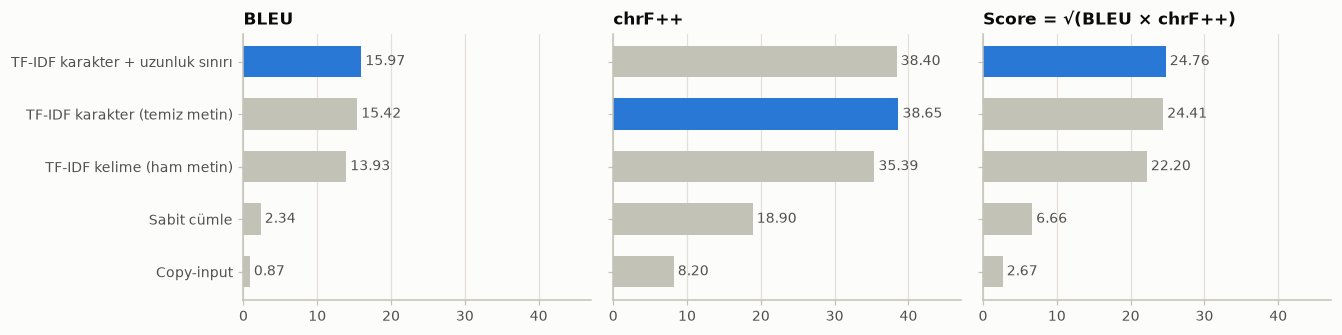

In [28]:
val_results = run_baselines(train_part, val_part)
display(val_results)
plot_baseline_scores(val_results)

**Yorum:** Validation'da (156 belge) sıralama net:

- **Copy-input 2.67.** Akadca ile İngilizce arasında ortak kelime yok denecek kadar az (BLEU 0.87). chrF++'ın 8.20 olması yalnızca ortak karakter dizilerinden (sayılar, özel isim parçaları) geliyor.
- **Sabit cümle 6.66.** İngilizce bir metin verdiği için karakter düzeyinde puan topluyor (chrF++ 18.90), ama BLEU 2.34. Bu, içeriğe hiç bakmadan alınabilecek skor.
- **TF-IDF kelime 22.20.** İçeriğe bakmak skoru üç katından fazla artırıyor. Tabletler kalıplaşmış (3.5); benzer bir borç senedinin çevirisi, isimler ve rakamlar yanlış olsa bile cümle iskeletini tutturuyor.
- **TF-IDF karakter 24.41.** Karakter n-gram ve ön işleme, kelime sürümüne göre +2.21 puan getiriyor. Kazanç iki metrikte de var (BLEU 13.93 → 15.42, chrF++ 35.39 → 38.65); seyrek sözlük sorununu karakter n-gramlar hafifletiyor.
- **Uzunluk sınırı eklenince 24.76.** BLEU artıyor (15.97), chrF++ çok az düşüyor (38.40). Fark küçük; ayrıntısı 5.3'te.

Grafikte her panelde en yüksek değer mavi. Paneller aynı ölçekte çizildiği için chrF++'ın TF-IDF yöntemlerinde BLEU'nun yaklaşık 2.5 katı olduğu görülüyor: çıktılar karakter düzeyinde doğru çeviriye benziyor ama kelimeleri tutturamıyor. Resmi metrik (sağ panel) geometrik ortalama olduğu için ikisinin arasında kalıyor ve chrF++'ın çizdiği iyimser tabloyu dengeliyor.

### 5.3 Çıktı uzunluğu sınırı (validation üzerinde ayar seçimi)

In [29]:
compare_length_caps(train_part, val_part)

,max_len_ratio,BLEU,chrF++,Score,ortalama çıktı (karakter)
0,sınır yok,15.42,38.65,24.41,610
1,4.0,15.78,38.79,24.75,596
2,3.0,15.97,38.40,24.76,569
3,2.0,16.03,36.94,24.34,503
4,1.5,14.50,35.16,22.58,444


**Yorum:** Çeviri belleği en benzer **belgenin tüm çevirisini** getiriyor. Getirilen çeviri girdiye göre çok uzunsa, fazladan gelen her kelime BLEU'nun kesinliğini düşürür. `max_len_ratio`, çıktıyı "girdi karakter sayısı × oran" sınırını aşmayacak şekilde **cümle sınırından** keser (ilk cümle her zaman kalır). Çeviri / kaynak oranının medyanı 1.08 olduğu için (3.4) 3.0 gevşek bir sınır: yalnızca bariz biçimde uzun çıktıları kırpıyor (ortalama çıktı 610 → 569 karakter).

Tabloya göre sınır yokken Score 24.41; oran 4.0 ve 3.0'da 24.75 ve 24.76; 2.0'da 24.34; 1.5'te 22.58. Sınır sıkılaştıkça BLEU önce artıyor, sonra doğru içerik de kesilmeye başladığı için iki metrik birden düşüyor. **En yüksek validation skorunu veren 3.0'ı seçtik.**

Açık olmak gerekirse: 3.0 ile sınırsız arasındaki +0.35 puan, 156 belgelik bir kümede gürültü düzeyinde. Bu ayarı asıl gerekçesi için tutuyoruz: gizli test **cümle düzeyinde** (2.3) ve orada tek bir cümle için tüm belgenin çevirisini döndürmek çok daha pahalıya patlar. Bunun örneği 6.2'de.

### 5.4 Ön işleme ve tokenizasyon kararları

İki kararı validation üzerinde sınıyoruz: (1) `Ḫ/ḫ → H/h` dönüşümü test yazımında işe yarıyor mu? (2) TF-IDF'in metni küçük harfe çevirmesi, BÜYÜK harfle yazılan Sümerogram bilgisini kaybettirip skoru düşürüyor mu?

In [30]:
robustness_to_h_spelling(train_part, val_part)

,Yöntem,Ön işleme,Score (train yazımı),Score (test yazımı: H/h),Fark
0,TF-IDF kelime,yok,22.20,21.80,-0.40
1,TF-IDF kelime,var,22.20,22.20,0.00
2,TF-IDF karakter,yok,24.45,24.38,-0.07
3,TF-IDF karakter,var,24.41,24.41,0.00


**Yorum:** Gizli testte `Ḫ/ḫ` yerine `H/h` olacağını biliyoruz (3.8). Bunu taklit etmek için validation kaynaklarında `Ḫ → H`, `ḫ → h` yaptık; train'e dokunmadık.

- Ön işleme **yokken** kelime tabanlı yöntem 22.20'den 21.80'e düşüyor (−0.40): `ḫa-muš-tim` ile `ha-muš-tim` artık farklı kelimeler. Karakter tabanlı yöntem daha dayanıklı (−0.07), çünkü tek harf farkı yalnızca birkaç n-gramı bozuyor.
- Ön işleme **varken** iki yöntemde de fark sıfır: iki yazım aynı biçime iniyor.

İki sonuç: (1) Ön işleme, train ile aynı yazımdaki validation'da skoru değiştirmiyor (24.45 ve 24.41); faydası train-test yazım farkını kapatmak. (2) Buradaki etki küçük, çünkü yalnızca tek bir harfi değiştirdik ve yöntem zaten yaklaşık eşleşmeye dayanıyor. Tam kelime eşleşmesine ya da sabit bir sözlüğe dayanan modellerde aynı fark çok daha yıkıcı olur.

In [31]:
compare_settings(train_part, val_part, {
    "küçük harfe çevir (seçilen)": {"lowercase": True},
    "büyük-küçük harf korunur": {"lowercase": False},
}, label="TF-IDF eşleştirmesi")

,TF-IDF eşleştirmesi,BLEU,chrF++,Score,ortalama çıktı (karakter)
0,küçük harfe çevir (seçilen),15.97,38.40,24.76,569
1,büyük-küçük harf korunur,15.84,38.52,24.70,575


**Yorum:** Büyük-küçük harfi korumak skoru neredeyse değiştirmiyor: 24.76 (küçük harf) ve 24.70 (harf korunur). 156 belgelik bir kümede 0.06 puanlık fark gürültü düzeyinde. Bunun nedeni, Sümerogramların küçük harfe çevrilse bile kendine özgü kalması: `kù.babbar` gibi noktayla ayrılmış diziler hece yazımında neredeyse hiç geçmiyor, yani BÜYÜK harfin taşıdığı bilgi arama için büyük ölçüde zaten korunuyor. Varsayılan ayarı (küçük harf) tutuyoruz. Çıktıyı da etkileyen üretici bir modelde (Assignment 2, ByT5) harf bilgisi korunacak; oradaki karar yeniden sınanmalı.

### 5.5 Held-out test skoru

Ayarlar validation üzerinde seçildi. Şimdi model train + validation (%80) ile yeniden kurulur ve daha önce hiç kullanılmamış held-out %20 üzerinde bir kez ölçülür.

In [32]:
train_val = pd.concat([train_part, val_part])
heldout_results = run_baselines(train_val, test_part)
heldout_results

,Baseline,BLEU,chrF++,Score
0,Copy-input,1.29,8.81,3.37
1,Sabit cümle,2.19,19.14,6.47
2,TF-IDF kelime (ham metin),15.49,34.15,23.00
3,TF-IDF karakter (temiz metin),15.81,37.03,24.19
4,TF-IDF karakter + uzunluk sınırı,17.17,37.49,25.37


**Yorum:** Held-out %20'de (313 belge; modelin ve ayar seçiminin hiç görmediği veri) seçilen baseline'ın skoru **25.37** (BLEU 17.17, chrF++ 37.49).

Sıralama validation ile aynı: Copy-input 3.37 < Sabit cümle 6.47 < TF-IDF kelime 23.00 < TF-IDF karakter 24.19 < uzunluk sınırlı 25.37. Validation'da seçilen ayarların held-out'ta da aynı yönde sonuç vermesi (24.76 → 25.37) seçimin validation'a aşırı uymadığını gösteriyor. Kelimeden karaktere geçiş +1.19, uzunluk sınırı +1.18 puan katkı yapıyor.

"TF-IDF kelime (ham metin)" satırı projenin ilk sürümündeki baseline ile aynı yöntem ve aynı 313 belge: BLEU 15.49, ilk sürümde raporlanan değerle birebir aynı. İlk sürüm resmi metriği raporlamıyordu; karşılığı 23.00.

Bu skorlar **belge düzeyinde** ölçüldü. Aynı modelin Kaggle'daki gizli testte aldığı skor çok daha düşük (private 8.18); karşılaştırma ve olası nedenler 6.1'de.

In [33]:
best_model = train_baseline(train_val)
heldout_predictions = predict(best_model, test_part)
show_predictions(test_part, heldout_predictions, rows=(0, 1, 2, 3), width=150)

,kaynak,referans,tahmin
satır,,,
0,10 ma-na KÙ.BABBAR ṣa-ru-pu-um ni-is-ḫa-sú DIRI ša-du-a-sú ša-bu ša tám-kà-ri-im a-na i-li-a ù ša ki-ma lá-qé-ep ù a-ḫa-ma 0.3333 ma-na KÙ.BABBAR ša t,"10 minas of refined silver, its excise added, his transport fee paid, belonging to the merchant, for Iliya and the representatives of Lā-qēp, and sepa","15 minas of silver, its excise added, his transport fee paid, Karwāya brought to my investors, witnessed by Anīnum, son of Šu-hubur, by Aššuriš-tikal,"
1,2-ší-ta na-áš-pé-ra-tum lá pá-tí-a-tum ša a-ta-ta DUMU ma-num-ba-lum-a-šùr a-ṣé-ri-a ú a-ṣé-er a-šùr-e-nam DUMU ku-bi-a 2-ší-ta na-áš-pé-ra-tum ša a-b,"2 (unopened) letters of Atata, son of Mannum-balum-Assur, addressed to me and to Assur-ennam, son of Kubiya; two (unopened) letters of our father to B","A tablet about 10 shekels of silver of Abiya, son of Uzua; a tablet about 21 shekels of silver of Peruʾahšu and Elālī, son of Šalim-Aššur; a tablet wi"
2,KIŠIB en-na-nim DUMU a-lá-bi₄-im KIŠIB a-gi-a DUMU PUZUR₄-a-šùr {d}IM.GAL DUMU bu-zi tap-pá-i-ni a-na a-wa-tim a-ni-a-tim kà-ru-um kà-ni-iš i-dí-ni-a-,"Sealed by Ennānum son of Ali-abum, by Agiya son of Puzur-Aššur; Adad-rabi son of Buzi was our (absent) partner. The Kanesh colony gave us for these pr","Seal of Zuba, son of Ennānum, seal of Puzur-Adad, son of Iddin-Ištar; Ali-abum, son of Ziya, was our companion. For these words the Kaneš colony made"
3,a-na ma-nu-ki-a-šùr na-áb-sú-in a-na-na ù da-ra-áš qí-bi-ma um-ma en-nam-a-šur-ma 1 ma-na KÙ.BABBAR ṣa-ru-pá-am ku-nu-ki-a 30 ma-na URUDU SIG₅ ku-nu-k,"To Mannum-kī-Aššur, Nab-Suen, Anna-anna and Daraš from Ennam-Aššur: As to the 1 mina of refined silver under my seal, 30 minas of good copper under my","To Ennānum, Aššur-bāni and Ali-ahum from Bēlum-bāni: Concerning the tin I wrote to you about, where I said: Give the tin to Bēlānum and let Bēlānum br"


**Yorum:** Dört örnek, baseline'ın neyi yapıp neyi yapamadığını gösteriyor.

Model **belge türünü ve kalıbı** doğru yakalıyor: 0. satırda *"... minas of silver, its excise added, his transport fee paid"* formülü, 2. satırda mühür listesi ve Kaneš kolonisi ifadesi, 3. satırda *"To X from Y:"* mektup açılışı referansla aynı iskelette.

Ama **içerik yanlış**: rakamlar (0. satırda 10 mina yerine 15), kişi adları (2. satırda mühür sahipleri Ennānum ve Agiya yerine Zuba ve Puzur-Adad) ve olayın kendisi başka bir tabletten geliyor. 2. satırda Ennānum ve Ali-abum adları tahminde de geçiyor, ama başka rollerde: model isimleri değil, benzer bir belgeyi buluyor. 1. satırda yalnızca tür benziyor (bir belge listesi), içerik tamamen farklı.

Çeviri belleği yeni bir cümle kuramadığı için bu kaçınılmaz: 25 puanın neredeyse tamamı ortak kalıplardan geliyor. Özel isimleri ve sayıları kaynaktan okuyup çeviriye taşıyabilen, yani gerçekten **üreten** bir model gerekiyor.

## 6. Kaggle submission (Kaggle teslimi)

**Yarışmanın durumu.** Yarışma 23 Mart 2026'da kapandı. Kaggle hâlâ **Late Submission** kabul ediyor: gönderim puanlanıyor (public + private skor), ama sıralamaya girmiyor.

**Gönderim biçimi.** Bu bir *Code Competition*: `submission.csv` elle yüklenmez. Kaggle üzerinde **interneti kapalı** çalışan bir notebook gizli test kümesini okuyup `submission.csv` üretir ve o notebook gönderilir.

**Bu teslimdeki durum.** Seçilen baseline 13.11.2026'da Late Submission ile gönderildi ve puanlandı: **Private 8.1842, Public 8.5489** (ekran görüntüsü: `submissions/late_submission_score.png`). Ayar seçimi ve baseline karşılaştırması train verisinden ayrılan %20'lik held-out kısmında yapıldığı için o skor da raporlanıyor.

### 6.1 Kaggle skoru, held-out skoru ve leaderboard ile karşılaştırma

In [34]:
# Kaggle Late Submission sonucu (13.11.2026) ve leaderboard / public notebook skorları
BIZIM_KAGGLE = {"Kaggle public": 8.5489, "Kaggle private": 8.1842}
satirlar = [
    ("Bizim baseline", "held-out %20 (belge düzeyi)", heldout_results.iloc[-1]["Score"]),
    ("Bizim baseline", "Kaggle public", BIZIM_KAGGLE["Kaggle public"]),
    ("Bizim baseline", "Kaggle private", BIZIM_KAGGLE["Kaggle private"]),
    ("Leaderboard 1.si (DataTech Club)", "Kaggle public", 41.6694),
    ("Leaderboard 1.si (DataTech Club)", "Kaggle private", 42.8957),
    ("En yüksek skorlu public notebook", "Kaggle public", 41.6),
    ("En çok oy alan public notebook (632 oy)", "Kaggle public", 35.9),
    ("Popüler başlangıç notebook'u, DPC Starter Infer (600 oy)", "Kaggle public", 26.8),
]
karsilastirma = pd.DataFrame(satirlar, columns=["Sistem", "Ölçüldüğü küme", "Score"])
karsilastirma["Aynı kümedeki skorumuza fark"] = (
    karsilastirma["Score"] - karsilastirma["Ölçüldüğü küme"].map(BIZIM_KAGGLE))
karsilastirma.round(2)

,Sistem,Ölçüldüğü küme,Score,Aynı kümedeki skorumuza fark
0,Bizim baseline,held-out %20 (belge düzeyi),25.37,NaN
1,Bizim baseline,Kaggle public,8.55,0.00
2,Bizim baseline,Kaggle private,8.18,0.00
3,Leaderboard 1.si (DataTech Club),Kaggle public,41.67,33.12
4,Leaderboard 1.si (DataTech Club),Kaggle private,42.90,34.71
5,En yüksek skorlu public notebook,Kaggle public,41.60,33.05
6,En çok oy alan public notebook (632 oy),Kaggle public,35.90,27.35
7,"Popüler başlangıç notebook'u, DPC Starter Infer (600 oy)",Kaggle public,26.80,18.25


**Yorum:** **Kaggle skorumuz: private 8.18, public 8.55.** Aynı model held-out'ta 25.37 almıştı; gizli testte bunun yaklaşık üçte birini alıyor. Skorun düşeceğini öngörmüştük, ama düşüşün bu kadar büyük olması önemli bir şey söylüyor: **belge düzeyindeki held-out doğrulaması bu yarışmada gerçek performansı ölçmüyor.**

Leaderboard ile aynı küme üzerinden karşılaştırınca (tablonun son sütunu): birincinin private'ta 34.71, public'te 33.12 puan gerisindeyiz; en çok oy alan public notebook'un 27.35, popüler başlangıç notebook'unun 18.25 puan gerisindeyiz. **Baseline'ımız leaderboard'un tepesinden yaklaşık 34-35 puan uzakta.** Public ve private skorlarımızın birbirine yakın olması (8.55 ve 8.18), düşük skorun gizli testin küçük bir parçasına özgü olmadığını, modelin genelinde zayıf kaldığını gösteriyor.

Held-out ile gizli test arasındaki farkın olası iki nedeni var. Bu çalışmada ikisinin payını birbirinden ayıramıyoruz:

1. **Cümle düzeyi.** Gizli test tek tek cümlelerden oluşuyor; çeviri belleği ise bir belgenin çevirisini döndürüyor. Uzunluk sınırı çıktıyı kısaltsa da fazladan gelen cümleler BLEU'nun kesinliğini ve chrF++'ı düşürüyor (6.2'deki örnek). Model doğru belgeyi bulsa bile cümlenin belgedeki yerini bilmiyor.
2. **Farklı tabletler.** Held-out belgeleri train ile aynı kaynaktan geliyor ve train'de birbirine çok benzeyen belgeler var (3.9'daki tekrarlar; 2.3'te örnek testin train'in içinde çıkması). Gizli test büyük olasılıkla train'de olmayan tabletlerden oluşuyor; o zaman çeviri belleğinin dayandığı "benzer bir belge train'de var" varsayımı çöküyor.

Assignment 2 için en önemli ders bu: modeller **cümle düzeyinde ve train'den ayrık tabletlerle kurulmuş** bir doğrulama kümesinde karşılaştırılmalı. Üst sıralardaki çözümlerin ortak noktası da belli: akademik yayınlardan çıkarılmış on binlerce ek cümle çifti ve ince ayarlanmış ByT5 modelleri (çoğunlukla model topluluğu ve MBR çözümleme ile).

### 6.2 `submission.csv` üretimi

Gönderimde model **tüm train verisiyle** kurulur. Aşağıdaki hücre public örnek test için `submission.csv` yazar ve biçimini doğrular.

In [35]:
final_model = train_baseline(preprocess(train_df))
submission = save_submission(test_df["id"], predict(final_model, test_df), "submission.csv")
validate_submission(submission, sample_sub["id"])
print("submission.csv yazıldı ve biçimi doğrulandı:", submission.shape)

sinirsiz = predict(train_baseline(preprocess(train_df), max_len_ratio=None), test_df)
display(pd.DataFrame({
    "girdi (karakter)": test_df[SRC_COL].str.len(),
    "çıktı: sınır yok": [len(tahmin) for tahmin in sinirsiz],
    "çıktı: sınır 3.0": submission["translation"].str.len(),
    "örnek çeviri": sample_sub["translation"].str.len(),
}))
submission.assign(translation=submission["translation"].str[:110] + "…")

submission.csv yazıldı ve biçimi doğrulandı: (4, 2)


,girdi (karakter),çıktı: sınır yok,çıktı: sınır 3.0,örnek çeviri
0,133,856,171,130
1,146,856,171,179
2,267,856,761,360
3,129,856,171,187


,id,translation
0,0,"Thus Kanesh, say to the -payers, our messenger, every single colony, and the trading stations: A letter of the…"
1,1,"Thus Kanesh, say to the -payers, our messenger, every single colony, and the trading stations: A letter of the…"
2,2,"Thus Kanesh, say to the -payers, our messenger, every single colony, and the trading stations: A letter of the…"
3,3,"Thus Kanesh, say to the -payers, our messenger, every single colony, and the trading stations: A letter of the…"


**Yorum:** Dosya yarışmanın istediği biçimde: `id` ve `translation` sütunları, testteki her `id` için boş olmayan tek bir satır. `validate_submission` bunu otomatik kontrol ediyor.

Uzunluk tablosu 5.3'teki kararın gerekçesini gösteriyor: sınır olmadan dört cümlenin her biri için 856 karakterlik **tüm belge çevirisi** dönüyor; sınırla çıktılar 171 / 171 / 761 / 171 karaktere iniyor. Örnek çeviriler 130-360 karakter.

Tahminlerin dördü de aynı cümleyle başlıyor. Nedeni 2.3'teki sızıntı: dört örnek cümle train'deki aynı belgenin parçaları; model dördü için de o belgeyi buluyor ve çevirisini baştan itibaren döndürüyor. İlk satır için bu doğru cümle; diğer üçü için doğru belge ama yanlış bölüm. Bu, belge düzeyinde bir belleğin cümle düzeyindeki testteki temel zayıflığı: doğru belgeyi bulsa bile **cümlenin belgedeki yerini** bilmiyor.

Örnek test train'in içinde olduğu için burada skor hesaplamıyoruz; gizli testteki gerçek skor 6.1'de (private 8.18, public 8.55).

### 6.3 Kaggle'a gönderilen notebook

Kaggle'da internet kapalı olduğu için bu depo orada klonlanamaz. `build_kaggle_notebook`, `src/` modüllerini içine gömen ve tek başına çalışan bir gönderim notebook'u üretir. Böylece Kaggle'da çalışan kod ile bu notebook'taki kod birebir aynıdır.

In [36]:
print("Üretilen dosya:", build_kaggle_notebook("submissions/kaggle_submission.ipynb"))

Üretilen dosya: submissions/kaggle_submission.ipynb


**Late Submission nasıl yapıldı**

1. Yarışma sayfasında **Late Submission**'a tıklandı, kurallar kabul edildi.
2. **Code → New Notebook → File → Import Notebook** ile `submissions/kaggle_submission.ipynb` yüklendi.
3. Sağ panelde yarışma verisinin ekli olduğu ve **Internet: Off** olduğu kontrol edildi.
4. **Save Version → Save & Run All (Commit)** ile kaydedildi; notebook sayfasında `submission.csv` için **Submit to Competition** seçildi. Kaggle bu versiyonu gizli test kümesiyle yeniden çalıştırıp skoru o çıktıdan hesaplıyor.

| Tarih | Yöntem | Public score | Private score | Ekran görüntüsü |
|---|---|---|---|---|
| 13.11.2026 | TF-IDF karakter + uzunluk sınırı (Late Submission) | 8.5489 | 8.1842 | `submissions/late_submission_score.png` |

## 7. Conclusion (Sonuç)

### Temel bulgular

1. **Veri küçük ve seyrek.** 1561 belge var; transliterasyon sözlüğünün %59'u yalnızca bir kez geçiyor. Kelime düzeyinde yöntemler baştan dezavantajlı.
2. **Train ve test aynı şey değil.** Train belge düzeyinde, test cümle düzeyinde; yazım kuralları da farklı (`Ḫ/ḫ` ve `H/h`, alt simgeler, `(ki)`, `…`). Public örnek test train'in içinde olduğu için yerel doğrulamada kullanılamıyor.
3. **Veride gürültü var.** Uzun tabletlerde transliterasyon yaklaşık 900 karakterde kesilmiş görünüyor, çeviri ise tam (68 belgede çeviri aykırı uzun); belgelerin %43'ü kırık (`<gap>`) içeriyor. Kesme hipotezi Assignment 2'de `published_texts.csv`'deki tam transliterasyonlarla doğrulanabilir.
4. **Ön işleme sıkıştırmıyor, hizalıyor.** Sözlük boyutunu değiştirmeden train'i testin yazımına çeviriyor; test yazımı taklit edildiğinde görülen skor kaybını sıfırlıyor.
5. **Baseline.** Karakter n-gram TF-IDF çeviri belleği ve uzunluk sınırı: validation 24.76, held-out 25.37 (BLEU 17.17, chrF++ 37.49). **Kaggle Late Submission: private 8.18, public 8.55**; leaderboard birincisinin (private 42.90) yaklaşık 34.7 puan gerisinde. Skorun kaynağı kalıplaşmış ifadeler; isimler ve rakamlar çoğunlukla yanlış.
6. **Yerel doğrulama yanıltıcıydı.** Belge düzeyindeki held-out skoru (25.37), gizli test skorunun (8.18) üç katı. Train'den rastgele ayrılan belgeler, yarışmanın cümle düzeyindeki ve büyük olasılıkla farklı tabletlerden oluşan testini temsil etmiyor.

### Bu teslimde düzeltilen hatalar

- Metrik fonksiyonu referansları `sacrebleu`'ya yanlış biçimde veriyor ve BLEU'yu 0 hesaplıyordu. Düzeltildi; artık resmi metrik raporlanıyor.
- Temizleme fonksiyonu `<gap>` etiketlerini bozuyordu. Düzeltildi ve örneklerle sınandı (Bölüm 4).

### Assignment 2 için sonraki adımlar

1. **Önce doğrulamayı düzeltmek.** `Sentences_Oare_FirstWord_LinNum.csv`, bazı train belgeleri için cümlelerin ilk kelime konumunu veriyor. Bununla belgeler cümlelere bölünüp test ile aynı biçime getirilebilir ve cümle düzeyinde, tablet bazında ayrık bir validation kümesi kurulabilir. Kaggle skoru (8.18) ile held-out skoru (25.37) arasındaki uçurum, bunun yapılmadan model seçmenin yanıltıcı olacağını gösteriyor.
2. **Üreten bir model.** Önceden eğitilmiş ByT5'in ince ayarı (önce small / base, kaynak yeterse large). Bayt düzeyinde çalıştığı için seyrek sözlük ve aksanlı karakter sorunlarını doğrudan çözüyor; yarışmanın üst sıralarındaki çözümlerin ortak seçimi. Colab GPU'da karma hassasiyetle (BF16 / FP16) eğitim.
3. **Veri temizliği.** Kaynağı kesilmiş, çeviri / kaynak uzunluk oranı aykırı belgelerin ayıklanması ya da çevirinin kırpılması.
4. **Ek veri ve sözlük.** `published_texts.csv` (yaklaşık 8000 transliterasyon) ile ön eğitim ya da geri çeviri (back-translation) yoluyla sentetik veri; `OA_Lexicon_eBL.csv` ile özel isimlerin doğru yazımı.
5. **Çözümleme.** Beam search ve uzunluk cezası; kaynak yeterse birden fazla aday arasından MBR ile seçim.
6. **Kaggle.** Late Submission yolu kuruldu (`submissions/kaggle_submission.ipynb`); Assignment 2 modelleri de aynı yolla gizli testte ölçülecek. Baseline'ın geçilmesi gereken gerçek çıta: private 8.18.